In [423]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.io as pio 
import plotly.express as px
import nbformat


Data Cleaning

In [424]:

rides = ['7_dwarfs_train', 'alien_saucers', 'astro_orbiter', 'big_thunder_mtn', 'buzz_lightyear', 'dinosaur', 'dumbo', 'expedition_everest', 'flight_of_passage', 'haunted_mansion', 'jungle_cruise', 'kilimanjaro_safaris', 'mad_tea_party', 'magic_carpets', 'navi_river', 'peoplemover', 'peter_pan_s_flight', 'pirates_of_caribbean', 'rock_n_rollercoaster', 'slinky_dog', 'soarin', 'space_mountain', 'splash_mountain', 'tom_land_speedway', 'toy_story_mania', 'winnie_the_pooh']
dfs = []
for ride in rides:
    df = pd.read_csv(f'/Users/brittneychan/Desktop/disneypred/data/raw/{ride}.csv.xls')
    df['ride'] = ride
    dfs.append(df)

all_rides = pd.concat(dfs)

#Day information (year, month, day, hour, day of week)
all_rides['datetime'] = pd.to_datetime(all_rides['datetime'])

all_rides['year'] = all_rides['datetime'].dt.year
all_rides['month'] = all_rides['datetime'].dt.month
all_rides['day'] = all_rides['datetime'].dt.day
all_rides['hour'] = all_rides['datetime'].dt.hour
all_rides['day_of_week'] = all_rides['datetime'].dt.dayofweek  # 0=Monday, 6=Sunday
all_rides['weekday_name'] = all_rides['datetime'].dt.day_name()

#Clean invalid wait times
all_rides.loc[all_rides['SACTMIN'] < 0, 'SACTMIN'] = np.nan
all_rides['SPOSTMIN'] = all_rides['SPOSTMIN'].replace(-999, np.nan)
all_rides['SACTMIN'] = all_rides['SACTMIN'].replace(-999, np.nan)

# Get rid of outliers
q1 = all_rides.groupby('ride')['SACTMIN'].transform('quantile', 0.25)
q3 = all_rides.groupby('ride')['SACTMIN'].transform('quantile', 0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
all_rides.loc[all_rides['SACTMIN'] > upper_bound, 'SACTMIN'] = np.nan


#Imputation of wait times
all_rides['posted_wait'] = all_rides['SPOSTMIN'].fillna(all_rides['SACTMIN'])
all_rides['posted_wait'] = all_rides.groupby(['ride', 'month', 'day_of_week', 'hour'])['posted_wait'].transform(lambda x: x.fillna(x.median()))

all_rides['posted_wait'] = all_rides.groupby('ride')['posted_wait'].transform(lambda x: x.fillna(x.median()))

#Get rid of unnecessary columns
all_rides.drop(columns=['SPOSTMIN', 'SACTMIN'], inplace=True)

/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/brittneychan/Libra

In [425]:
meta = pd.read_csv('/Users/brittneychan/Desktop/disneypred/data/raw/metadata.csv.xls')
season = meta[['DATE','SEASON']]
season.head()

,DATE,SEASON
0,01/01/2015,CHRISTMAS PEAK
1,01/02/2015,CHRISTMAS
2,01/03/2015,CHRISTMAS
3,01/04/2015,CHRISTMAS
4,01/05/2015,CHRISTMAS


In [426]:
#Kissimmee Weather Data 
kissimmee = pd.read_csv('/Users/brittneychan/Desktop/disneypred/data/raw/kissimmee.csv').drop(columns=['COOPID'])
kissimmee.columns = kissimmee.columns.str.strip().str.lower()

kissimmee['weatherdate'] = pd.to_datetime(kissimmee[['year', 'month', 'day']])

weather_cols = ['precipitation', 'mean temp']

# Set date as index
kissimmee = kissimmee.sort_values('weatherdate')
kissimmee = kissimmee.set_index('weatherdate')

#Impute missing values - 7 day rolling avg
weathercols = ['mean temp', 'max temp', 'min temp']

for col in weathercols:
    kissimmee[col] = kissimmee[col].replace(-99.9, np.nan)
    kissimmee[col] = kissimmee[col].fillna(
        kissimmee[col].rolling(
            window=7,
            center=True,
            min_periods=1
        ).mean()
    )

kissimmee['precipitation'] = kissimmee['precipitation'].replace([-99.99, -99.9], np.nan)
kissimmee['precipitation'] = kissimmee['precipitation'].fillna(
    kissimmee['precipitation'].rolling(7, center=True, min_periods=1).median()
)

kissimmee = kissimmee.reset_index()
kissimmee.head()

,weatherdate,year,month,day,precipitation,max temp,min temp,mean temp
0,2015-01-01,2015,1,1,0.02,65.0,58.0,61.5
1,2015-01-02,2015,1,2,0.00,75.0,59.0,67.0
2,2015-01-03,2015,1,3,0.00,77.0,61.0,69.0
3,2015-01-04,2015,1,4,0.00,85.0,67.0,76.0
4,2015-01-05,2015,1,5,0.00,86.0,66.0,76.0


In [455]:
fin = all_rides.merge(season, left_on='date', right_on='DATE', how='left').merge(
    kissimmee,
    left_on=['year', 'month', 'day'],
    right_on=['year', 'month', 'day'],
    how='left'
)
fin.drop(columns=['DATE', 'weatherdate'], inplace=True)
fin.rename(columns={'SEASON': 'season'}, inplace=True)
fin.head()

,date,datetime,ride,year,month,day,hour,day_of_week,weekday_name,posted_wait,season,precipitation,max temp,min temp,mean temp
0,01/01/2015,2015-01-01 07:51:12,7_dwarfs_train,2015,1,1,7,3,Thursday,45.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
1,01/01/2015,2015-01-01 08:02:13,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
2,01/01/2015,2015-01-01 08:05:30,7_dwarfs_train,2015,1,1,8,3,Thursday,54.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
3,01/01/2015,2015-01-01 08:09:12,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
4,01/01/2015,2015-01-01 08:16:12,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5


Exploring Data

In [428]:
print(min(fin['posted_wait']))
print(max(fin['posted_wait']))
print(fin['posted_wait'].describe())

0.0
390.0
count    6.969147e+06
mean     3.964193e+01
std      3.175113e+01
min      0.000000e+00
25%      1.500000e+01
50%      3.000000e+01
75%      5.500000e+01
max      3.900000e+02
Name: posted_wait, dtype: float64


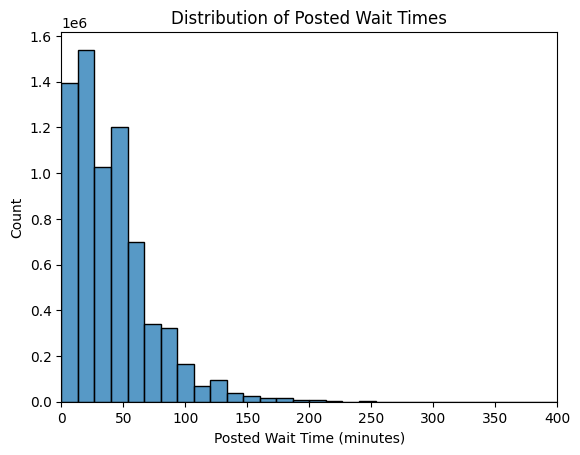

In [429]:
# Distribution of wait time
sns.histplot(fin['posted_wait'], bins=30, binrange=(0, 400))
plt.title('Distribution of Posted Wait Times')
plt.xlabel('Posted Wait Time (minutes)')
plt.xlim(0, 400)
plt.show()

ride
flight_of_passage       53.595932
space_mountain          35.376589
7_dwarfs_train          33.836941
navi_river              32.396631
rock_n_rollercoaster    31.651389
toy_story_mania         29.996143
splash_mountain         29.925376
kilimanjaro_safaris     28.293731
slinky_dog              28.091067
soarin                  27.270648
peter_pan_s_flight      24.903827
jungle_cruise           24.424845
big_thunder_mtn         23.007078
expedition_everest      22.473513
buzz_lightyear          19.584987
dinosaur                19.250036
haunted_mansion         18.729021
pirates_of_caribbean    17.862752
alien_saucers           16.106781
dumbo                   15.393380
tom_land_speedway       14.822725
winnie_the_pooh         13.777666
astro_orbiter           13.344797
magic_carpets           11.099860
peoplemover             10.026762
mad_tea_party            7.797398
Name: posted_wait, dtype: float64


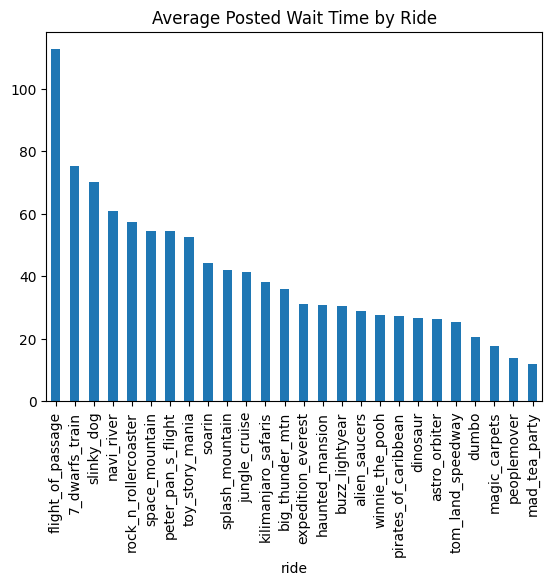

<Figure size 1200x600 with 0 Axes>

In [430]:
# Ride vs wait time
rideavg = fin.groupby('ride')['posted_wait'].mean().sort_values(ascending=False)
rideavg.plot(kind='bar')
plt.title('Average Posted Wait Time by Ride')
plt.figure(figsize=(12, 6))

print(fin.groupby('ride')['posted_wait'].std().sort_values(ascending=False))

(0.0, 24.0)

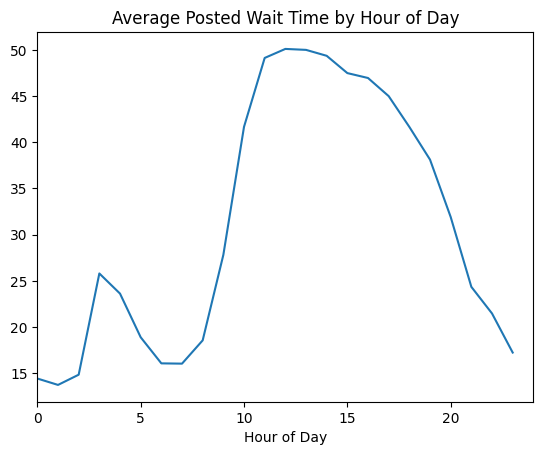

In [431]:
# Hour of day vs wait time
hourly = fin.groupby('hour')['posted_wait'].mean()
sns.lineplot(x=hourly.index, y=hourly.values)
plt.title('Average Posted Wait Time by Hour of Day')
plt.xlabel('Hour of Day')
plt.xlim(0, 24)

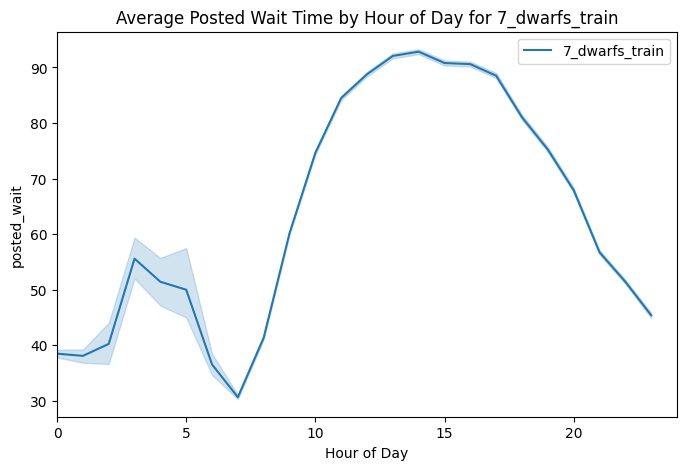

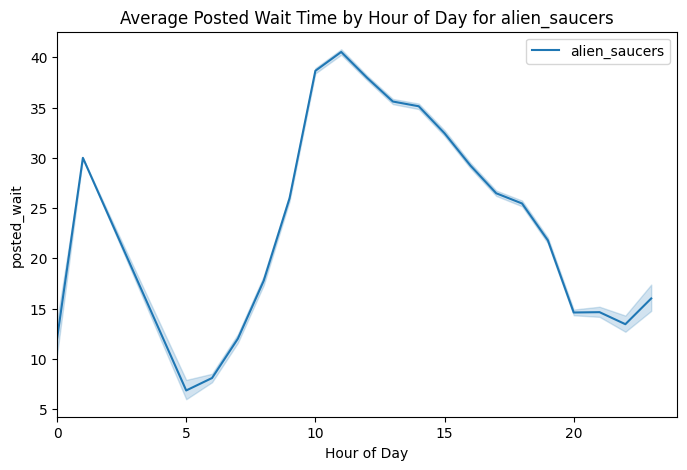

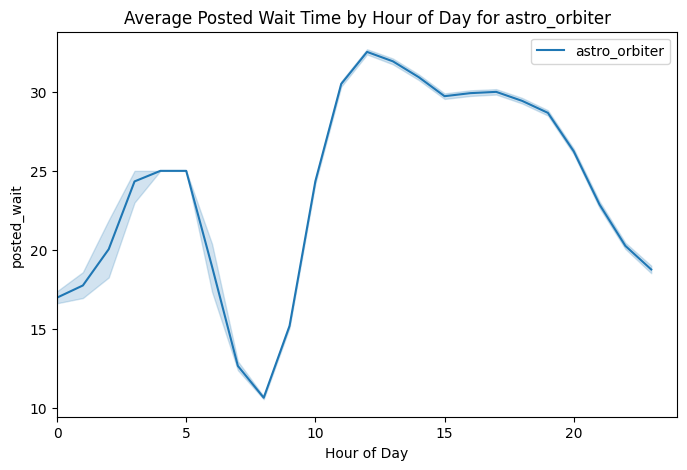

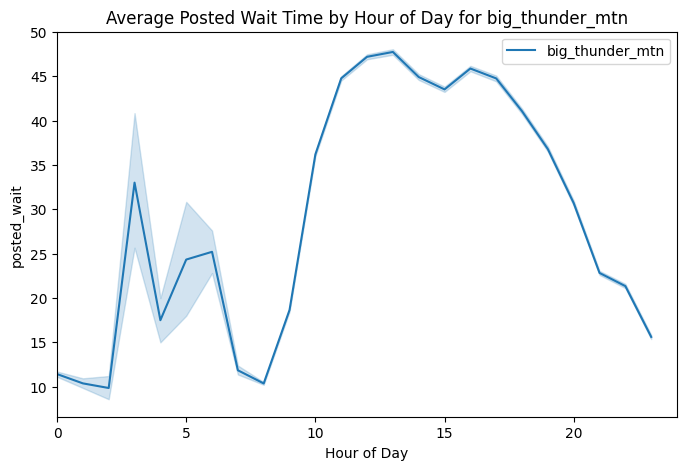

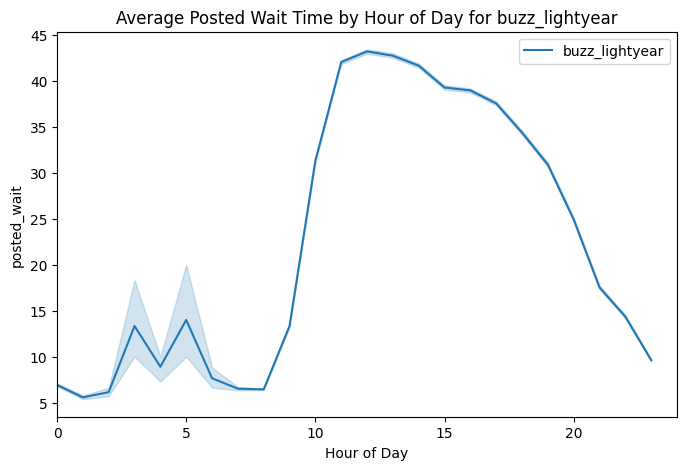

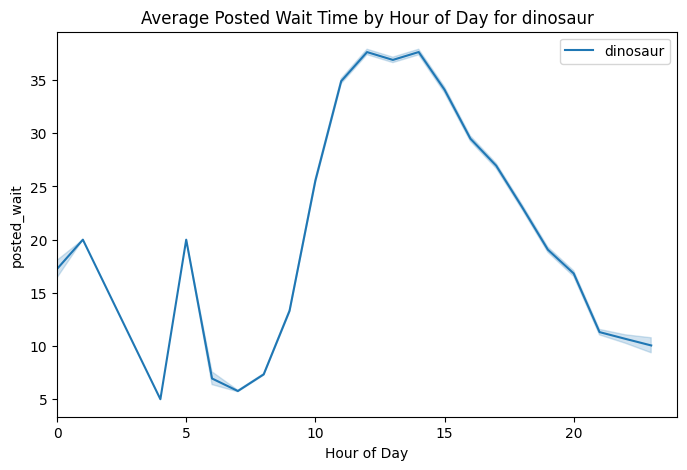

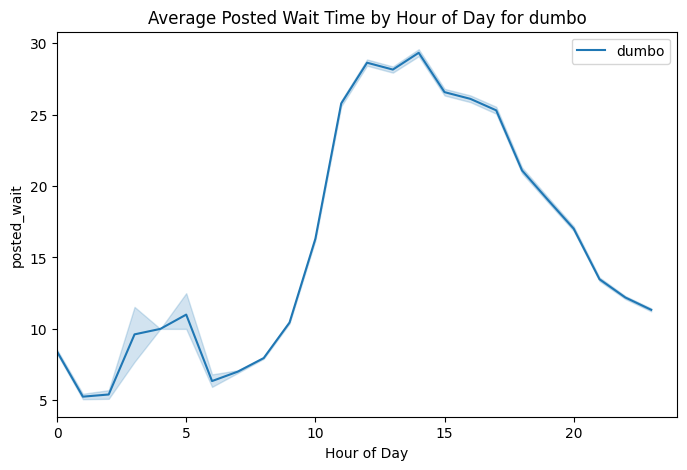

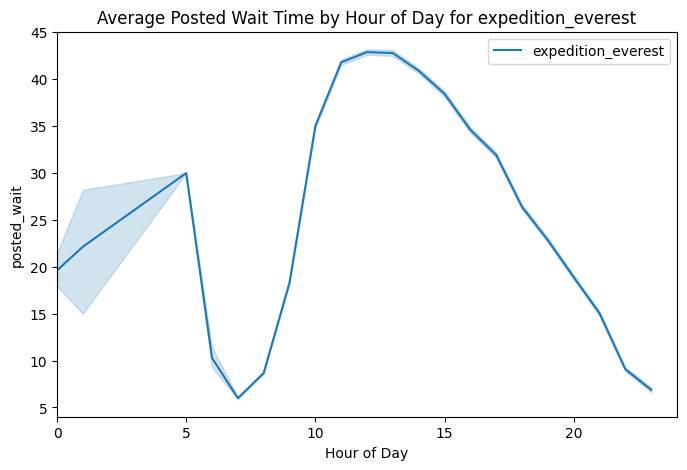

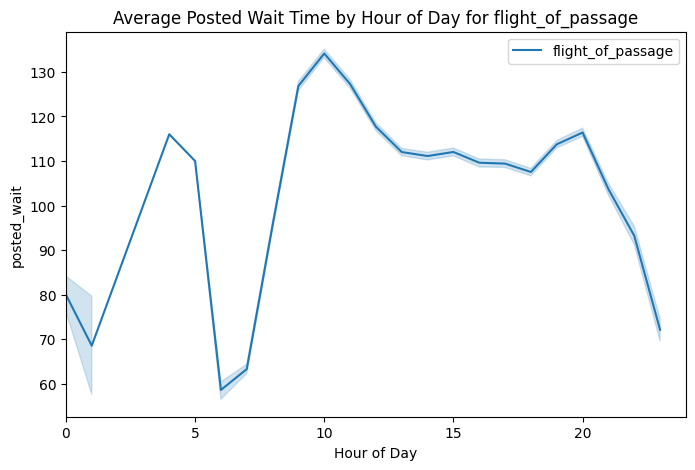

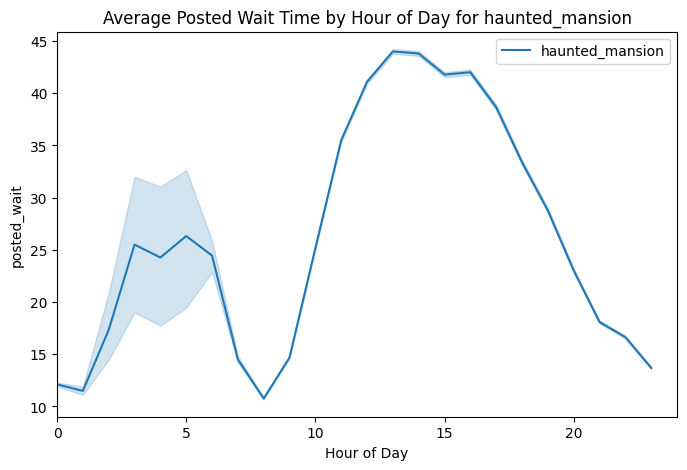

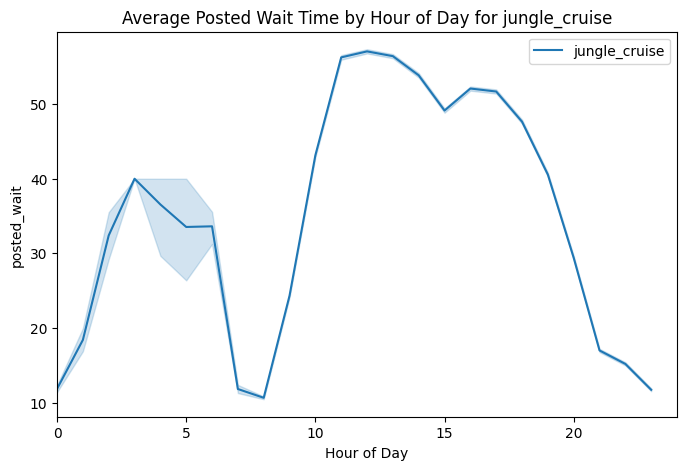

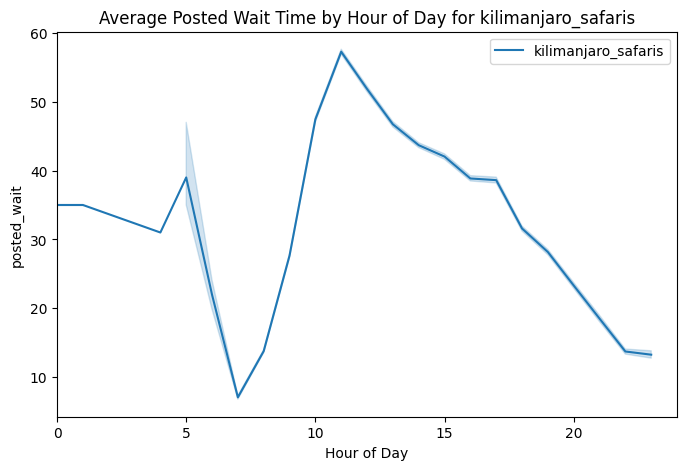

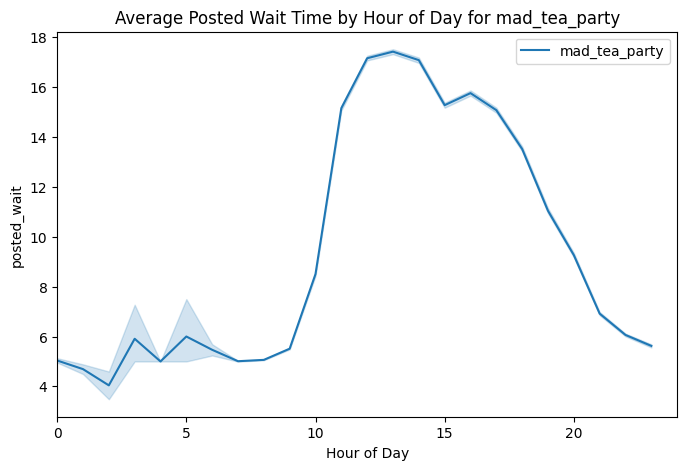

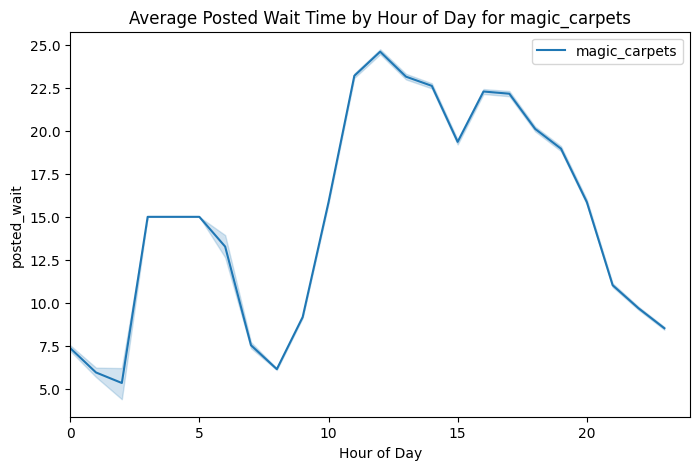

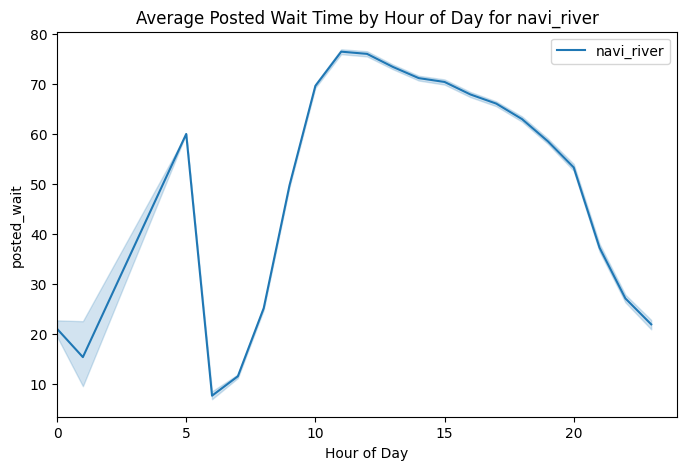

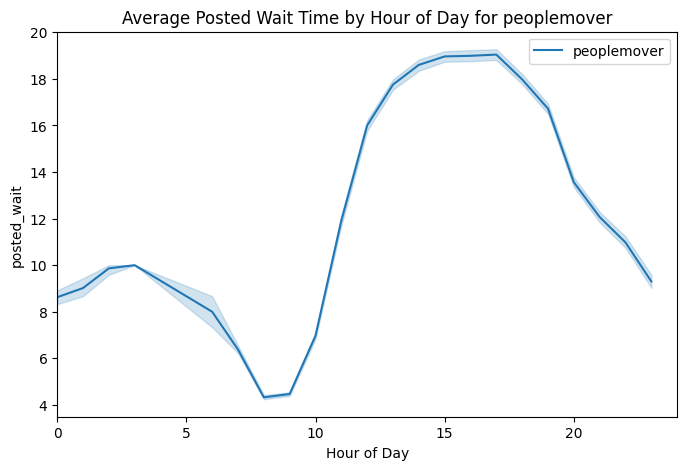

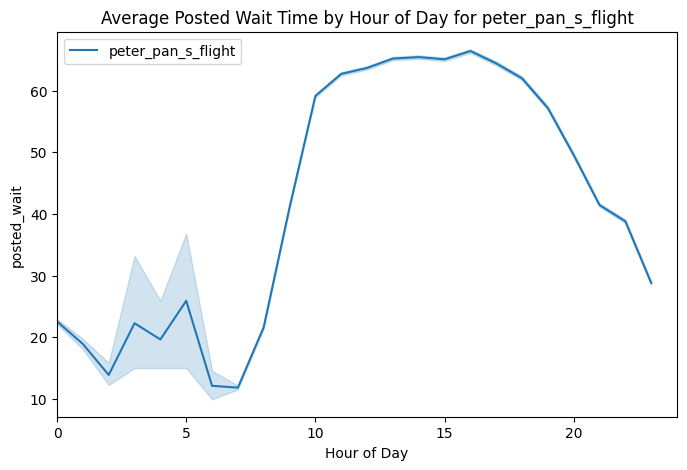

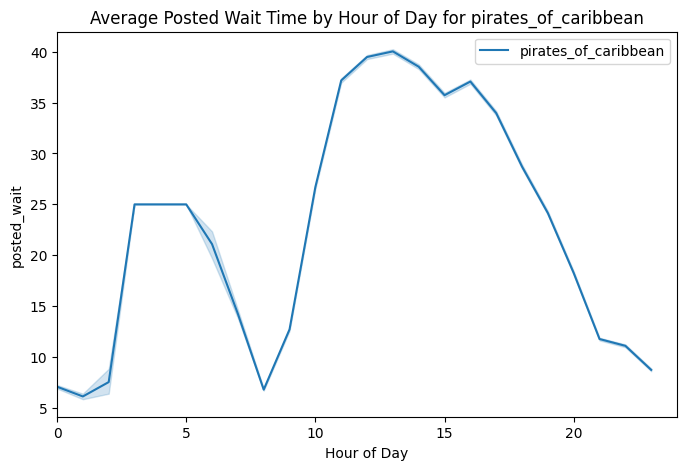

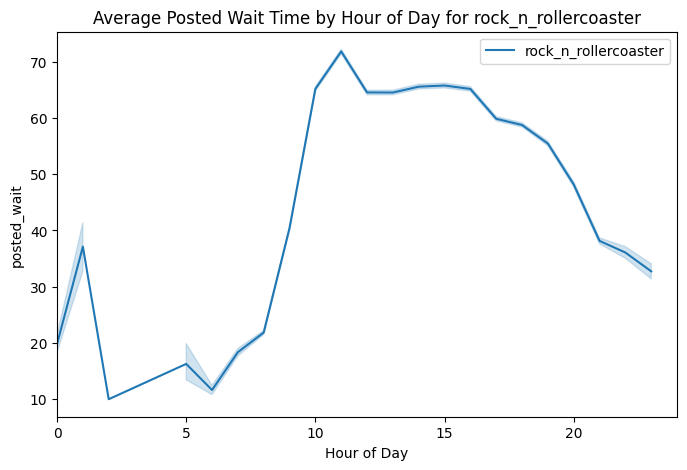

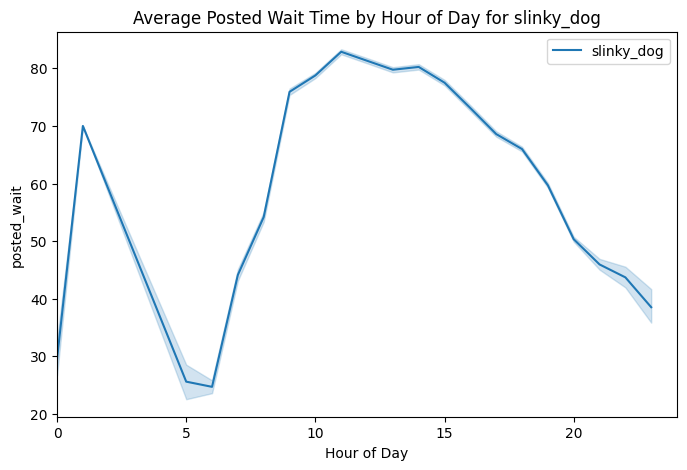

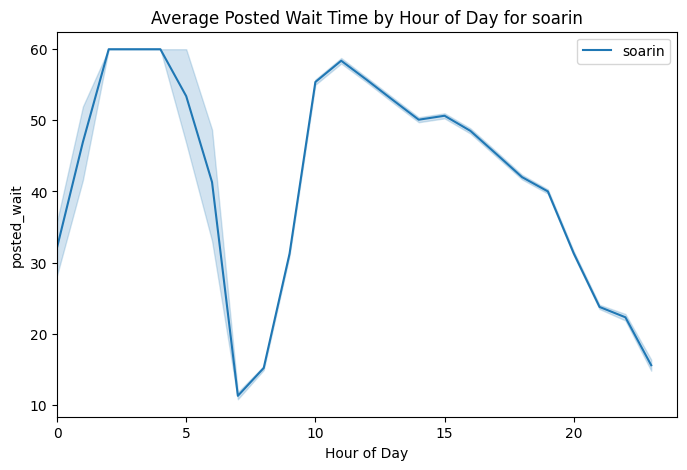

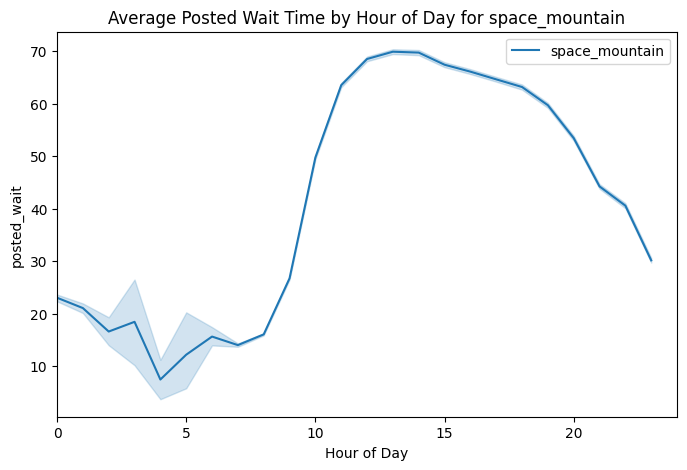

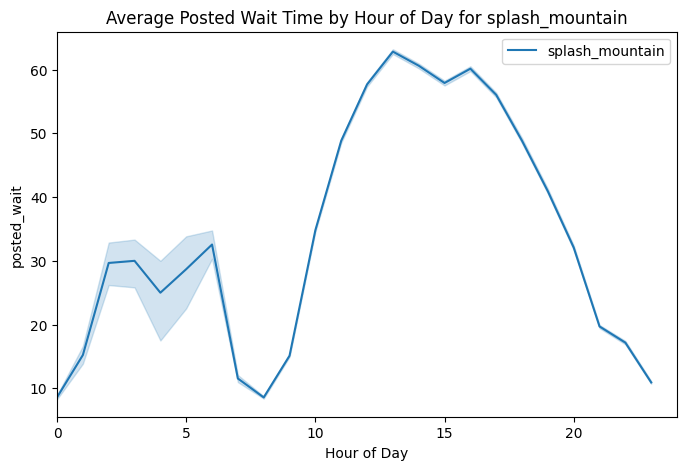

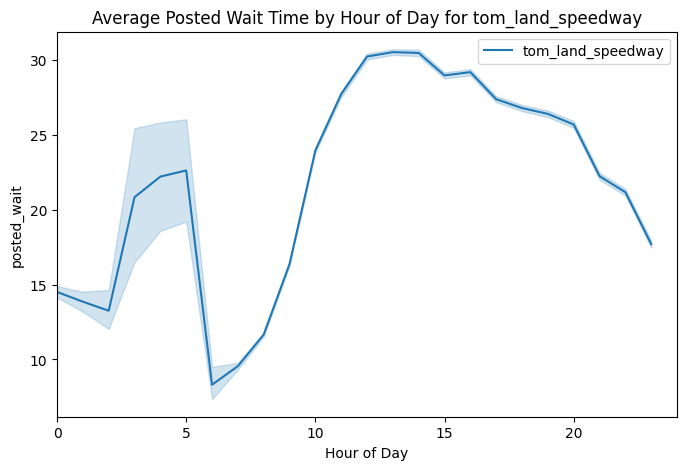

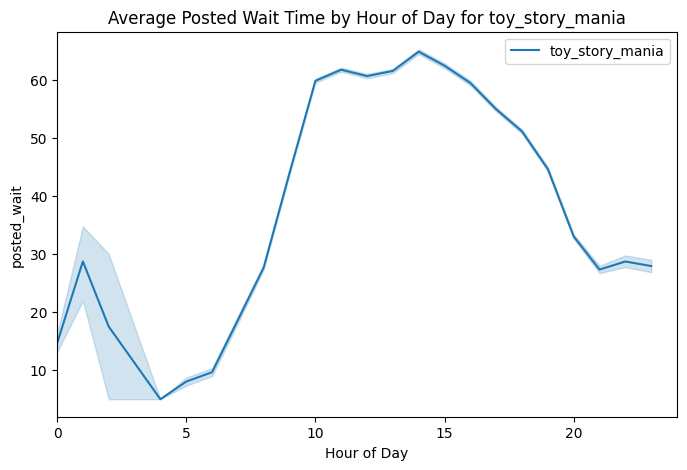

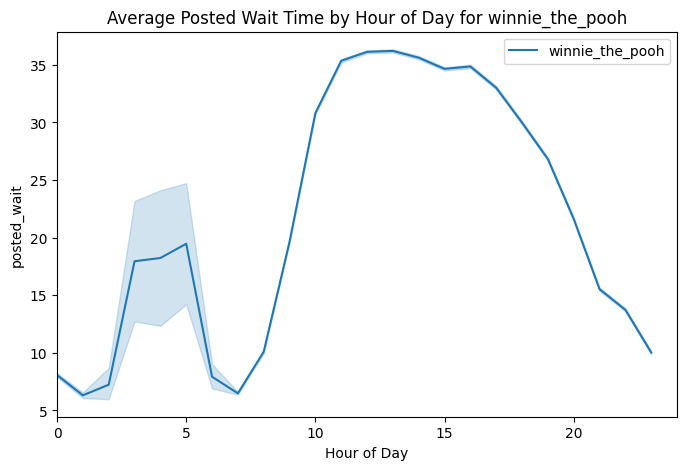

In [432]:
for ride in rides:
    ride_data = fin[fin['ride'] == ride]
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=ride_data,
        x='hour',
        y='posted_wait',
        label=ride
    )
    plt.title(f'Average Posted Wait Time by Hour of Day for {ride}')
    plt.xlabel('Hour of Day')
    plt.xlim(0, 24)
    plt.show()

<Axes: xlabel='hour', ylabel='posted_wait'>

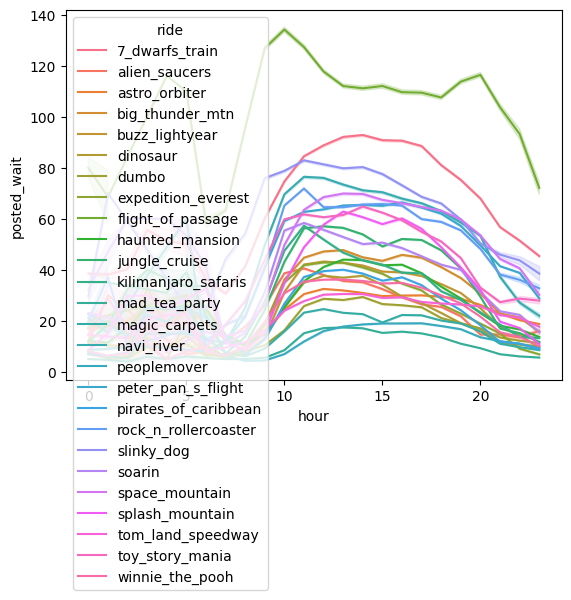

In [ ]:
sns.lineplot(
    data=fin,
    x='hour',
    y='posted_wait',
    hue='ride'
)

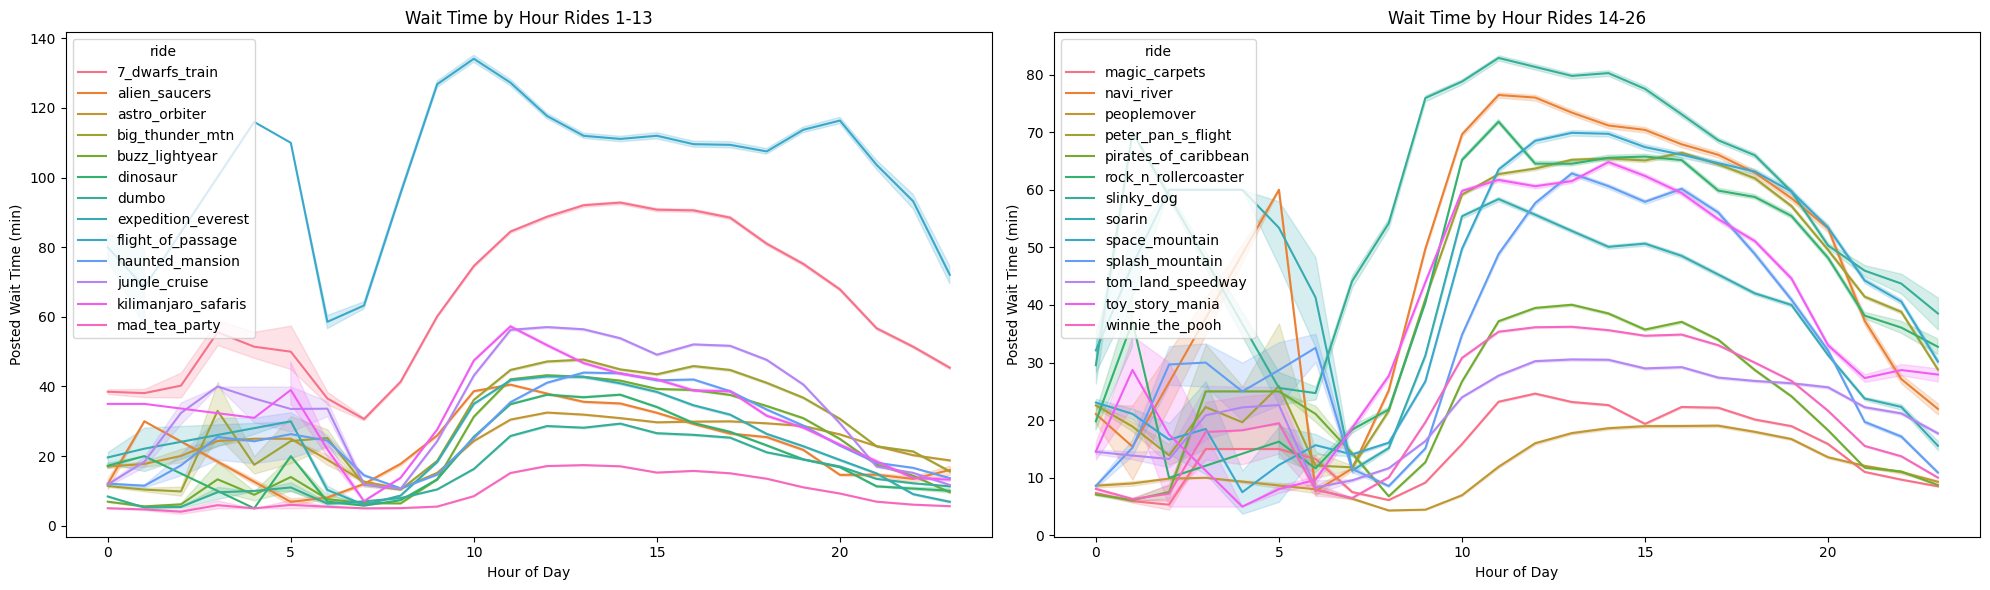

In [452]:
half = len(rides) // 2
first = rides[:half]
second = rides[half:]

fig, axes = plt.subplots(1, 2, figsize=(20, 6))

sns.lineplot(
    data=fin[fin['ride'].isin(first)],

    x='hour',
    y='posted_wait',
    hue='ride',
    ax=axes[0]
)
axes[0].set_title('Wait Time by Hour Rides 1-13')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Posted Wait Time (min)')

sns.lineplot(
    data=fin[fin['ride'].isin(second)],
    x='hour',
    y='posted_wait',
    hue='ride',
    ax=axes[1]
)
axes[1].set_title('Wait Time by Hour Rides 14-26')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Posted Wait Time (min)')

plt.tight_layout()
plt.show()

<Axes: xlabel='day_of_week'>

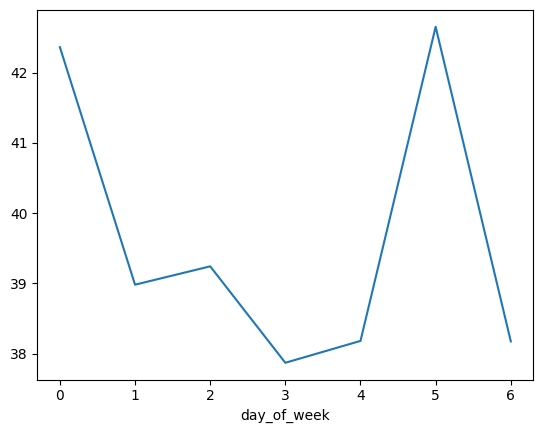

In [434]:
# Day of week vs wait time
#0 = Monday, 6 = Sunday
dayofweek = fin.groupby('day_of_week')['posted_wait'].mean()
sns.lineplot(x=dayofweek.index, y=dayofweek.values)

season
CHRISTMAS PEAK     63.126676
CHRISTMAS          49.660974
EASTER             48.109466
THANKSGIVING       48.108122
MARDI GRAS         47.583400
PRESIDENTS WEEK    47.507164
MEMORIAL DAY       46.432504
COLUMBUS DAY       44.229043
JULY 4TH           42.759622
SUMMER BREAK       42.689405
MLK JR             41.617906
SPRING             41.502309
JERSEY WEEK        40.222186
WINTER             37.473138
FALL               34.139208
HALLOWEEN          31.253956
SEPTEMBER LOW      29.460394
Name: posted_wait, dtype: float64


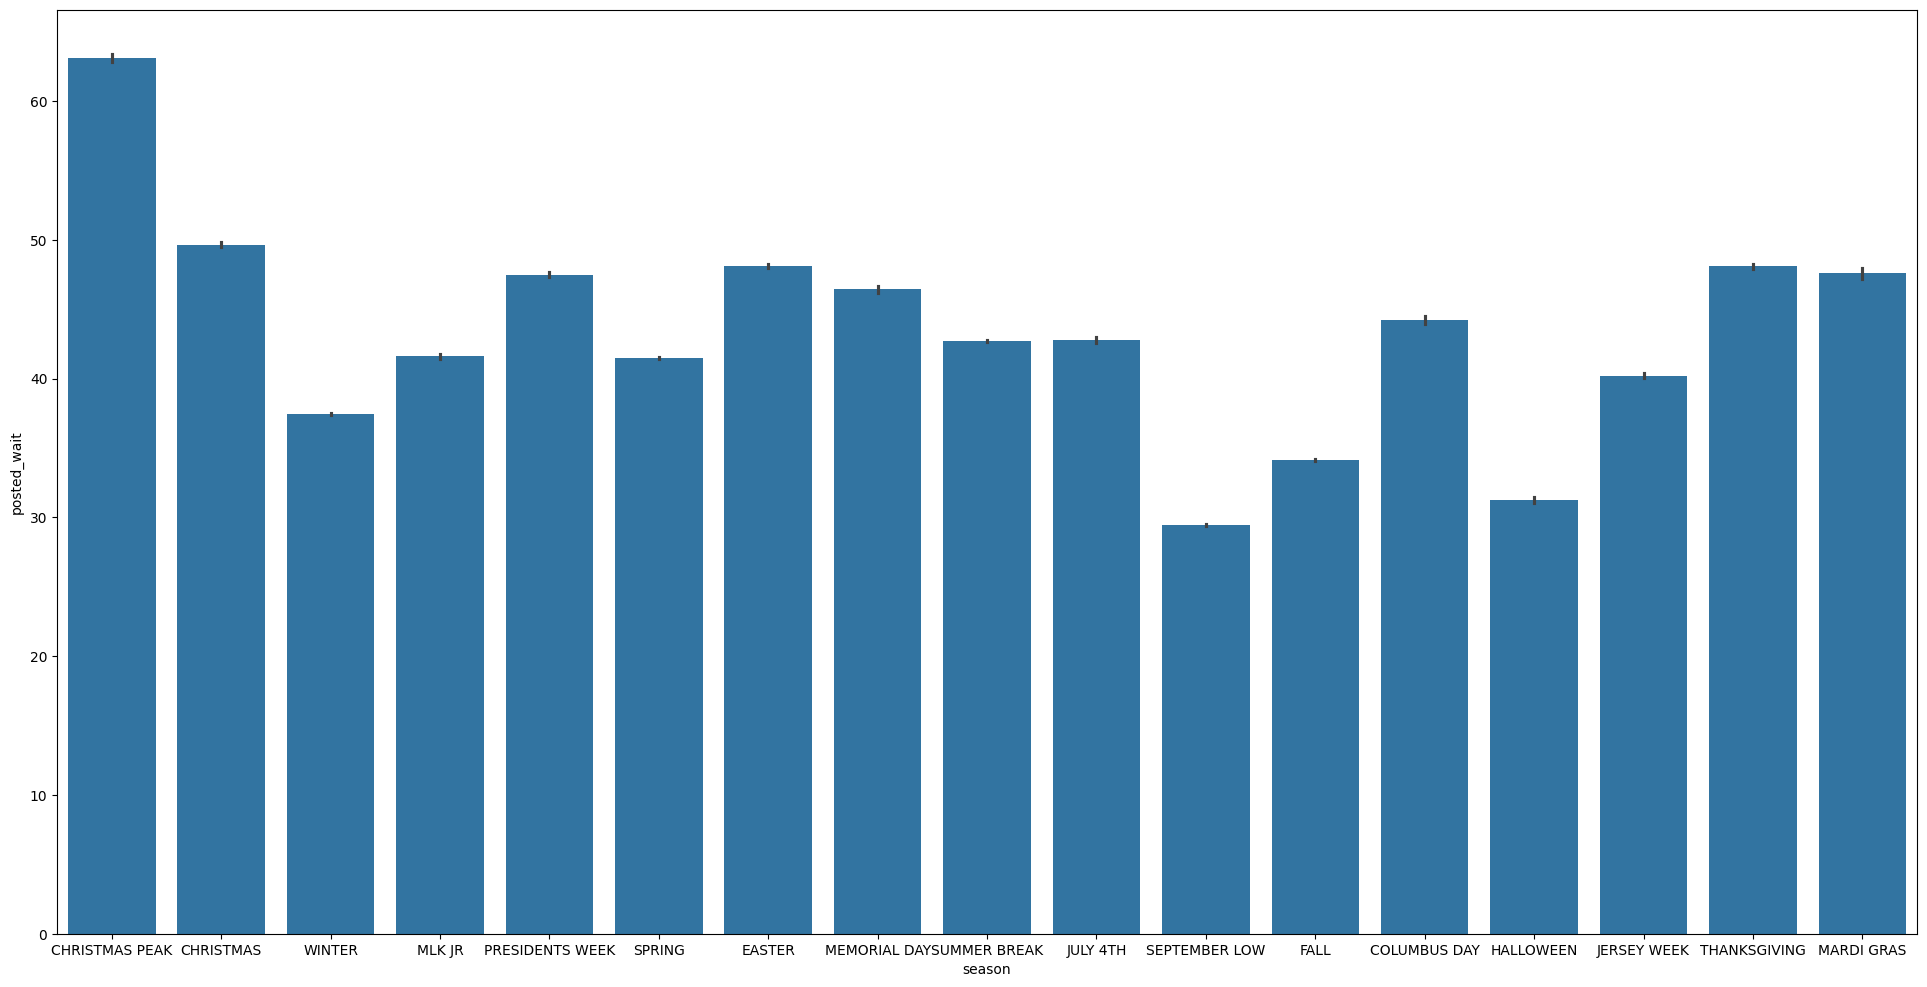

In [435]:
# Season vs wait time
mapping = {'MARTIN LUTHER KING JUNIOR DAY': 'MLK JR'}
fin['season'] = fin['season'].replace(mapping)

seasonal = fin.groupby('season')['posted_wait'].mean().sort_values(ascending=False)
print(seasonal)

plt.figure(figsize=(24, 12))
sns.barplot(
    data=fin,
    x='season',
    y='posted_wait'
)
plt.show()

In [436]:
# Temperature vs wait time
pio.renderers.default = "browser" 

finsample = fin.sample(n=5000).copy()
finsample['temp_step'] = finsample['mean temp'].round()
finsample = finsample.sort_values('temp_step')

fig = px.scatter(
    finsample, 
    x='mean temp', 
    y='posted_wait',
    animation_frame='temp_step',  # This creates your temperature slider!
    opacity=0.6,
    labels={'mean temp': 'Mean Temperature', 'posted_wait': 'Posted Wait Time (min)'},
    title="Wait Time vs. Temperature"
)

fig.update_layout(
    xaxis=dict(range=[finsample['mean temp'].min() - 2, finsample['mean temp'].max() + 2]),
    yaxis=dict(range=[0, finsample['posted_wait'].max() + 10])
)

fig.show()


/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


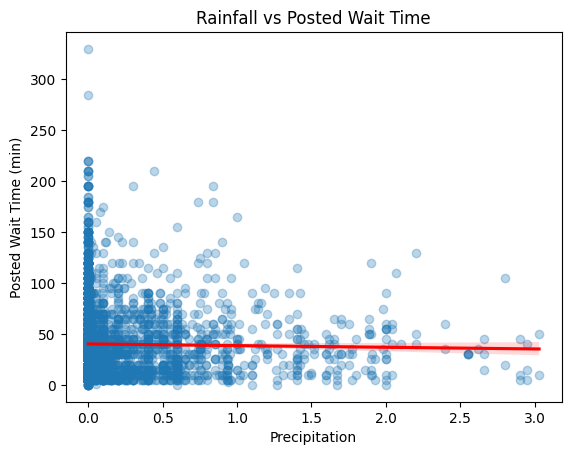

In [437]:
# Rain vs wait time
sns.regplot(
    data=fin.sample(n=5000),
    x='precipitation',
    y='posted_wait',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Rainfall vs Posted Wait Time')
plt.xlabel('Precipitation')
plt.ylabel('Posted Wait Time (min)')
plt.show()

/var/folders/hm/14j83hg521g_k5p6t8vj0zgh0000gn/T/ipykernel_16677/771093463.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fin.groupby(rainbins)['posted_wait']


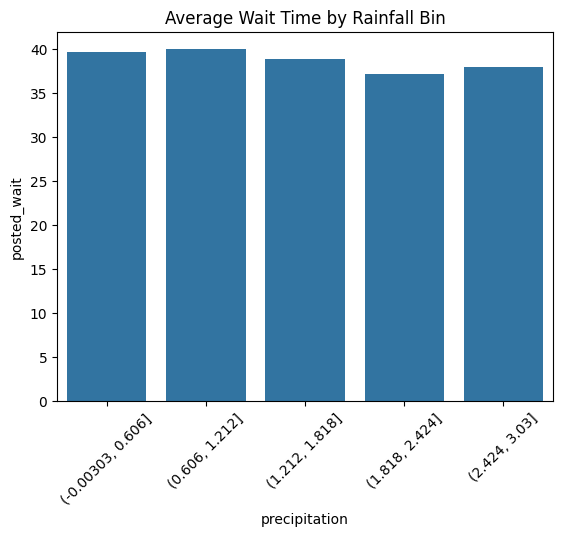

In [438]:
rainbins = pd.cut(fin['precipitation'], bins=5)

avgwait = (
    fin.groupby(rainbins)['posted_wait']
       .mean()
       .reset_index()
)

sns.barplot(
    data=avgwait,
    x='precipitation',
    y='posted_wait'
)

plt.xticks(rotation=45)
plt.title('Average Wait Time by Rainfall Bin')
plt.show()

<Axes: xlabel='date'>

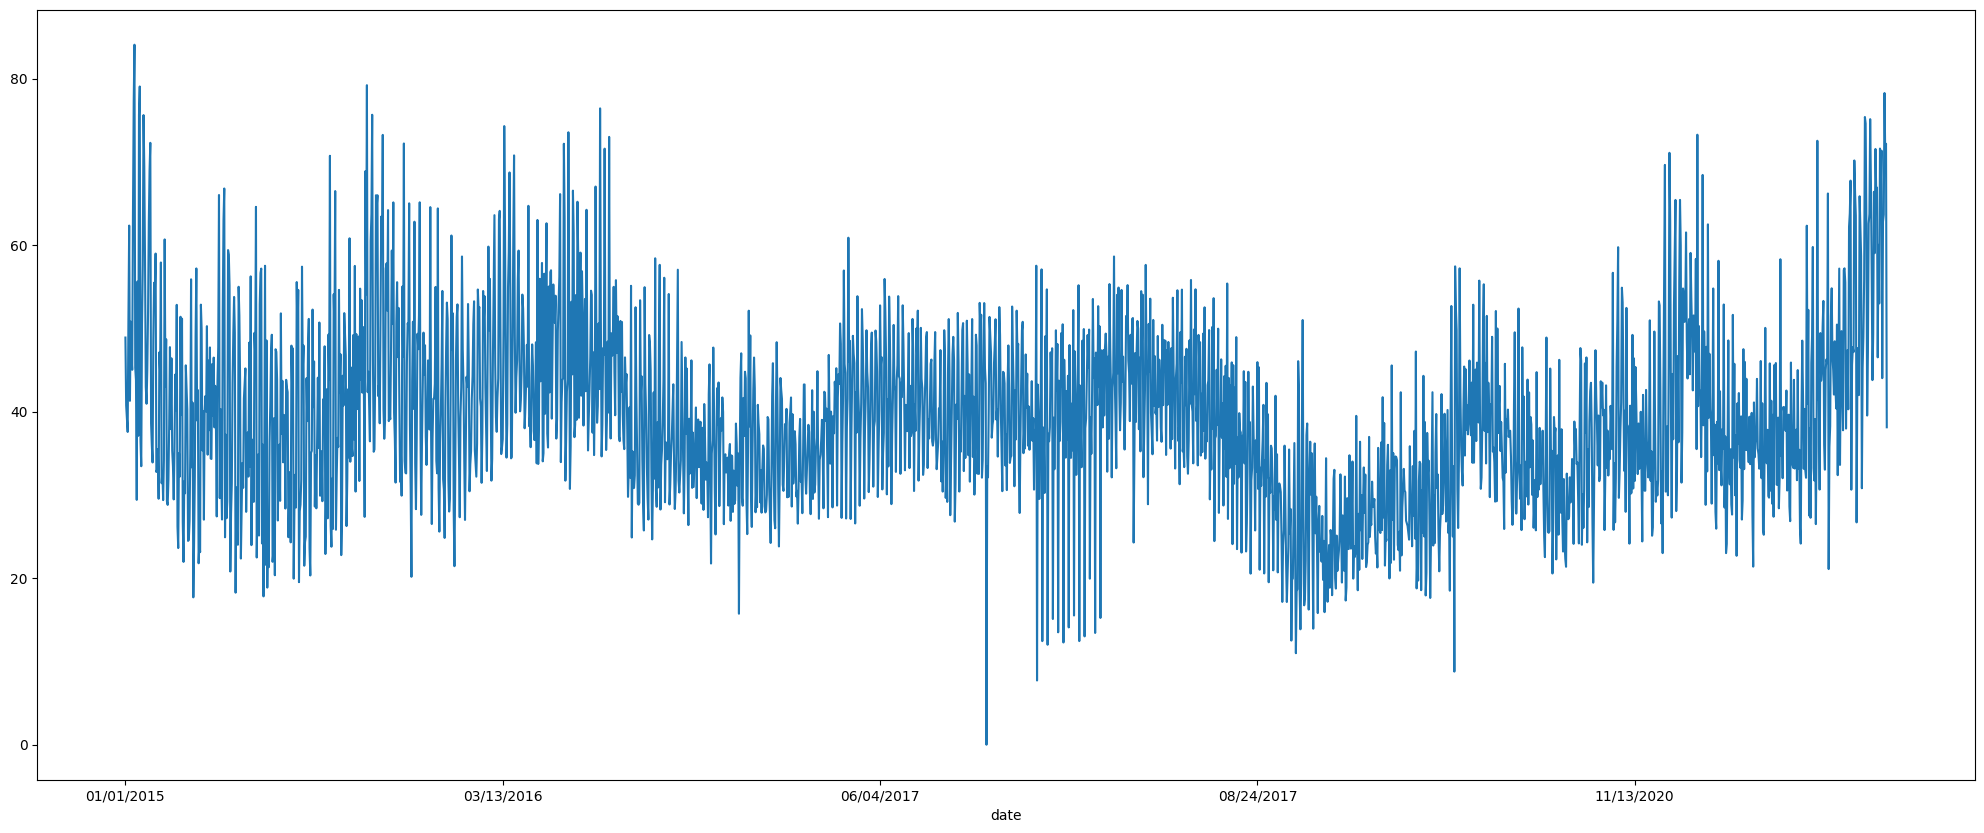

In [439]:
# Change over time
daily = (
    fin.groupby('date')['posted_wait']
      .mean()
)

daily.plot(figsize=(25,10))

<Axes: >

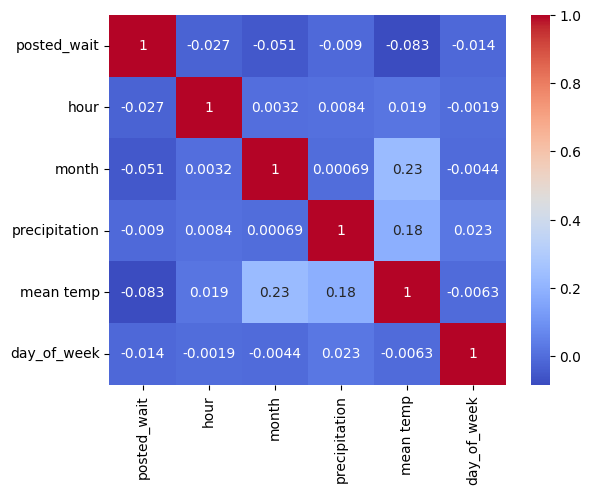

In [440]:
# Corr
col = [
    'posted_wait',
    'hour',
    'month',
    'precipitation',
    'mean temp',
    'day_of_week'

]

corr = fin[col].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')

<Axes: >

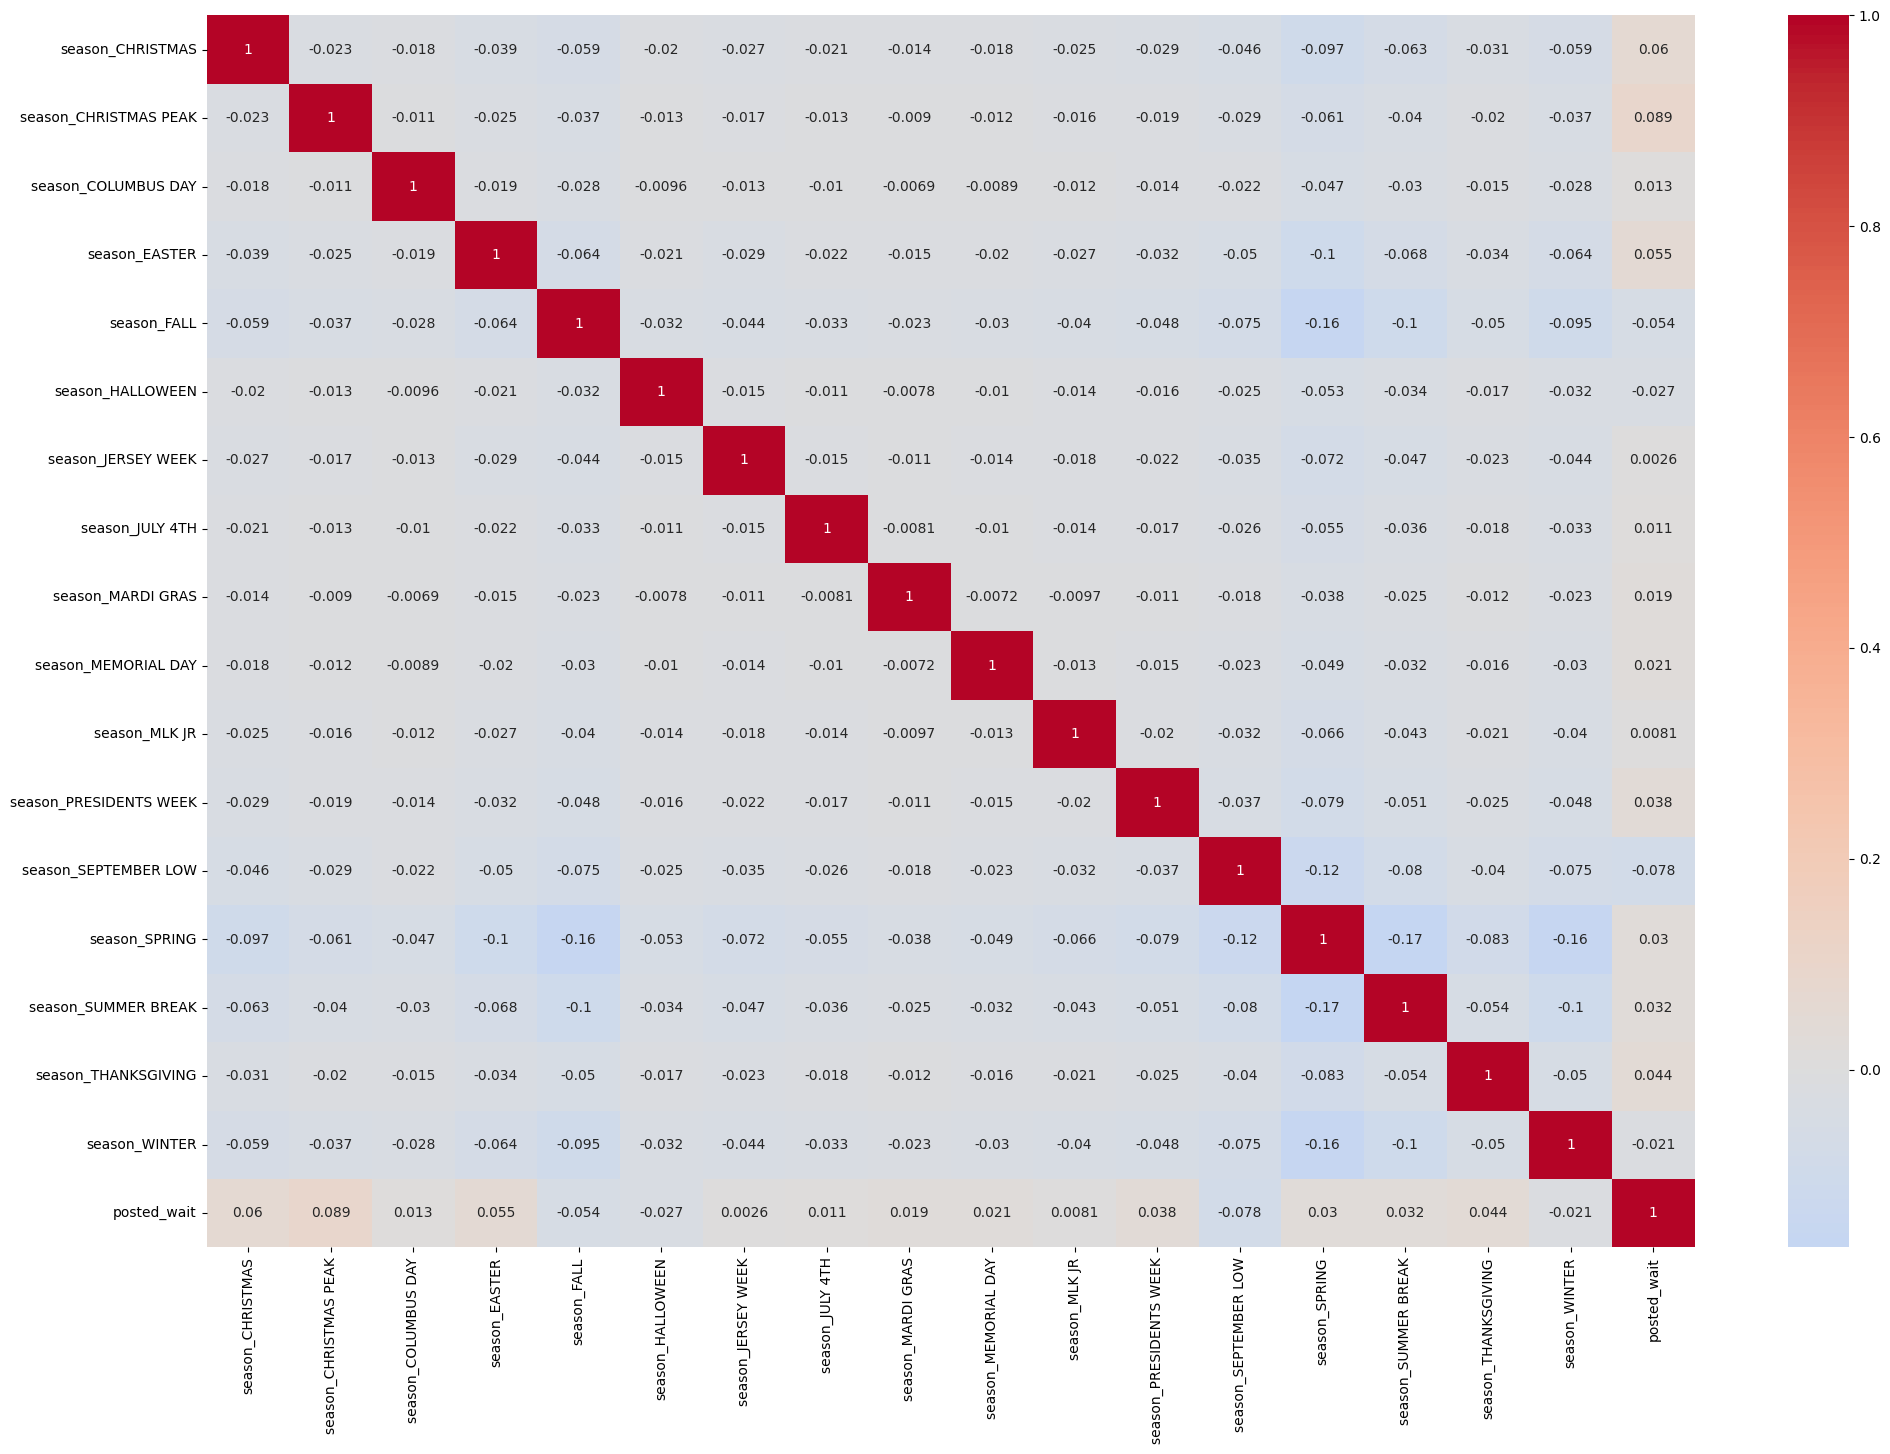

In [441]:
finseasons = fin[['season', 'posted_wait']]

seasondummies = pd.get_dummies(finseasons['season'], prefix='season')
corrdf = pd.concat([seasondummies, finseasons['posted_wait']], axis=1)
corr = corrdf.corr()

plt.figure(figsize=(24,16))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)

<Axes: xlabel='season', ylabel='hour'>

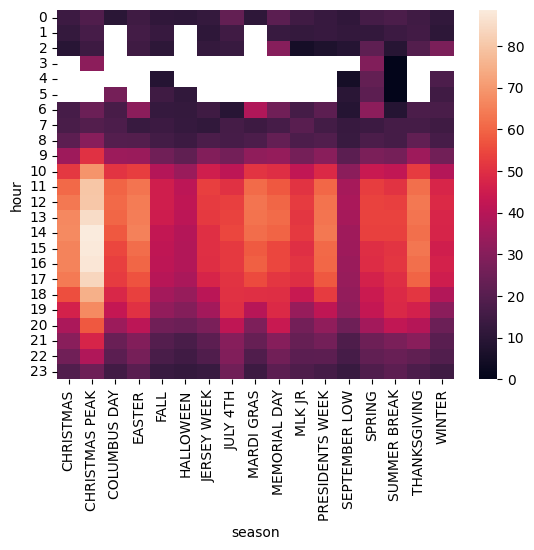

In [442]:
# Interactions
pivot = fin.pivot_table(
    values='posted_wait',
    index='hour',
    columns='season',
    aggfunc='mean'
)

sns.heatmap(pivot)

<Axes: xlabel='ride', ylabel='hour'>

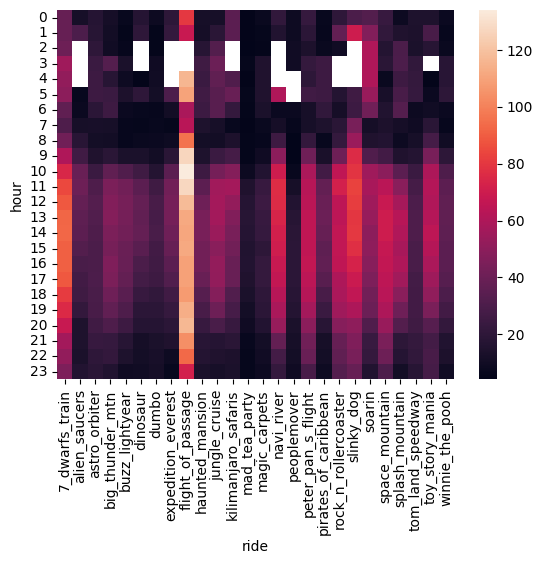

In [443]:
pivot = fin.pivot_table(
    values='posted_wait',
    index='hour',
    columns='ride',
    aggfunc='mean'
)

sns.heatmap(pivot)

Feature Engineering

In [444]:
split_index = int(len(fin) * 0.8)

train = fin.iloc[:split_index].copy()
test = fin.iloc[split_index:].copy()


def create_features(df):
    df = df.copy()

    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

    df['temp_range'] = df['max temp'] - df['min temp']

    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    df['week_of_year'] = df['datetime'].dt.isocalendar().week.astype(int)

    df['day_of_year'] = df['datetime'].dt.dayofyear

    df = df.drop(columns=['datetime', 'date', 'weekday_name'])
    
    return df


train = create_features(train)
test = create_features(test)


train = pd.get_dummies(train, columns=['ride', 'season'], drop_first=True)
test = pd.get_dummies(test, columns=['ride', 'season'], drop_first=True)



train, test = train.align(test, join='left', axis=1, fill_value=0)


X_train = train.drop('posted_wait', axis=1).dropna()
y_train = train['posted_wait'].loc[X_train.index]

X_test = test.drop('posted_wait', axis=1).dropna()
y_test = test['posted_wait'].loc[X_test.index]

In [445]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = LinearRegression()
model.fit(X_train, y_train)

preds = model.predict(X_test)

linearmae = mean_absolute_error(y_test, preds)
linearrmse = np.sqrt(mean_squared_error(y_test, preds))

print("Linear Regression MAE:", linearmae)
print("Linear Regression RMSE:", linearrmse)

Linear Regression MAE: 40.52635884005754
Linear Regression RMSE: 44.495940755958024


/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [446]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

preds = rf.predict(X_test)

rfmae = mean_absolute_error(y_test, preds)
rfrmse = np.sqrt(mean_squared_error(y_test, preds))

print("RF MAE:", rfmae)
print("RF RMSE:", rfrmse)

RF MAE: 22.603986281967195
RF RMSE: 27.6927584979722


ride_flight_of_passage       0.254658
hour                         0.113779
year                         0.082471
ride_mad_tea_party           0.050511
hour_cos                     0.049072
day_of_year                  0.047554
ride_magic_carpets           0.033831
ride_slinky_dog              0.029756
ride_dumbo                   0.029085
ride_peter_pan_s_flight      0.025935
ride_navi_river              0.025486
month_sin                    0.023757
ride_rock_n_rollercoaster    0.020905
ride_astro_orbiter           0.015889
ride_peoplemover             0.015169
dtype: float64


<Axes: >

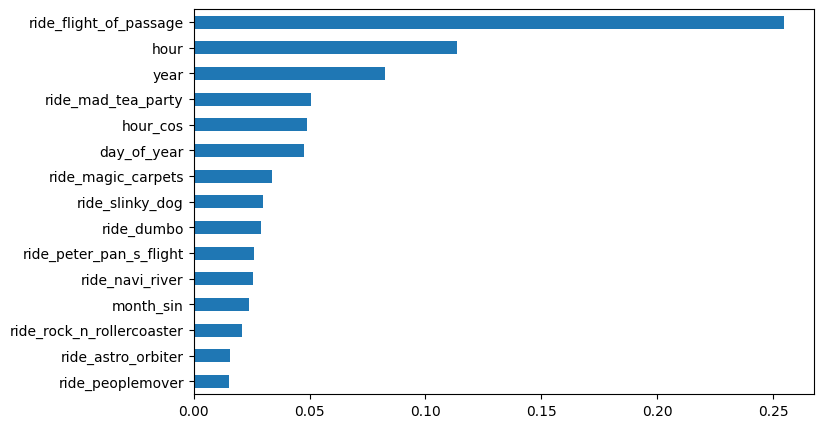

In [447]:
importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))
importance.head(15).sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

In [448]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

preds = xgb.predict(X_test)

xgbmae = mean_absolute_error(y_test, preds)
xgbrmse = np.sqrt(mean_squared_error(y_test, preds))

print("XGBoost MAE:", xgbmae)
print("XGBoost RMSE:", xgbrmse)


XGBoost MAE: 24.194093980719792
XGBoost RMSE: 28.083095303252165


In [449]:
importance = pd.Series(
    xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))

ride_flight_of_passage       0.321726
ride_mad_tea_party           0.082900
ride_magic_carpets           0.062643
ride_slinky_dog              0.059974
ride_dumbo                   0.052983
ride_peoplemover             0.041290
ride_astro_orbiter           0.041058
ride_dinosaur                0.035373
ride_pirates_of_caribbean    0.031192
ride_buzz_lightyear          0.027283
ride_haunted_mansion         0.025804
ride_navi_river              0.025417
ride_peter_pan_s_flight      0.025411
ride_rock_n_rollercoaster    0.019810
ride_expedition_everest      0.019752
dtype: float32


In [453]:
print("Linear Regression MAE:", linearmae)
print("Linear Regression RMSE:", linearrmse)
print("RF MAE:", rfmae)
print("RF RMSE:", rfrmse)
print("XGBoost MAE:", xgbmae)
print("XGBoost RMSE:", xgbrmse)

Linear Regression MAE: 40.52635884005754
Linear Regression RMSE: 44.495940755958024
RF MAE: 22.603986281967195
RF RMSE: 27.6927584979722
XGBoost MAE: 24.194093980719792
XGBoost RMSE: 28.083095303252165


In [456]:
def predict_wait_time(ride, date_str, hour, mean_temp, precipitation, season):
    """
    Predict wait time for a given ride and conditions.
    
    Example:
    predict_wait_time('flight_of_passage', '2024-06-15', 14, 85, 0.0, 'SUMMER BREAK')
    """
    import pandas as pd
    import numpy as np

    date = pd.to_datetime(date_str)
    
    # Build input row
    input_data = {
        'year': date.year,
        'month': date.month,
        'day': date.day,
        'hour': hour,
        'day_of_week': date.dayofweek,
        'precipitation': precipitation,
        'mean temp': mean_temp,
        'max temp': mean_temp + 5,   # approximate if unknown
        'min temp': mean_temp - 5,
        'is_weekend': int(date.dayofweek in [5, 6]),
        'temp_range': 10,
        'month_sin': np.sin(2 * np.pi * date.month / 12),
        'month_cos': np.cos(2 * np.pi * date.month / 12),
        'hour_sin': np.sin(2 * np.pi * hour / 24),
        'hour_cos': np.cos(2 * np.pi * hour / 24),
        'week_of_year': date.isocalendar()[1],
        'day_of_year': date.dayofyear,
        'ride': ride,
        'season': season
    }
    
    input_df = pd.DataFrame([input_data])
    input_df = pd.get_dummies(input_df, columns=['ride', 'season'])
    
    # Align to training columns
    input_df = input_df.reindex(columns=X_train.columns, fill_value=0)
    
    rf_pred = rf.predict(input_df)[0]
    xgb_pred = xgb.predict(input_df)[0]
    lr_pred = model.predict(input_df)[0]
    
    print(f"Predicted wait time for {ride} at {hour}:00:")
    print(f"  Random Forest: {rf_pred:.1f} min")
    print(f"  XGBoost:       {xgb_pred:.1f} min")
    print(f"  Linear Reg:    {lr_pred:.1f} min")
    print(f"  Average:       {np.mean([rf_pred, xgb_pred]):.1f} min")



In [464]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, mean_absolute_error

kf = KFold(n_splits=5, shuffle=False)

mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)

# Random Forest CV
rf_cv_scores = cross_val_score(rf, X_train, y_train, cv=kf, scoring=mae_scorer, n_jobs=-1)
print("Random Forest CV MAE:", -rf_cv_scores.mean().round(2), "±", rf_cv_scores.std().round(2))

# XGBoost CV
xgb_cv_scores = cross_val_score(xgb, X_train, y_train, cv=kf, scoring=mae_scorer, n_jobs=-1)
print("XGBoost CV MAE:", -xgb_cv_scores.mean().round(2), "±", xgb_cv_scores.std().round(2))

Random Forest CV MAE: 29.19 ± 4.27
XGBoost CV MAE: 26.15 ± 3.69


In [465]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [2, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=KFold(n_splits=3, shuffle=False),
    scoring='neg_mean_absolute_error',
    verbose=2,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best RF params:", rf_grid.best_params_)
print("Best RF CV MAE:", -rf_grid.best_score_.round(2))

# Evaluate best RF on test set
best_rf = rf_grid.best_estimator_
rf_preds = best_rf.predict(X_test)
print("Best RF Test MAE:", mean_absolute_error(y_test, rf_preds).round(2))
print("Best RF Test RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)).round(2))

Fitting 3 folds for each of 18 candidates, totalling 54 fits


KeyboardInterrupt: 

In [ ]:
from xgboost import XGBRegressor

# --- XGBoost ---
xgb_param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_grid=xgb_param_grid,
    cv=KFold(n_splits=3, shuffle=False),
    scoring='neg_mean_absolute_error',
    verbose=2,
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print("Best XGB params:", xgb_grid.best_params_)
print("Best XGB CV MAE:", -xgb_grid.best_score_.round(2))

# Evaluate best XGB on test set
best_xgb = xgb_grid.best_estimator_
xgb_preds = best_xgb.predict(X_test)
print("Best XGB Test MAE:", mean_absolute_error(y_test, xgb_preds).round(2))
print("Best XGB Test RMSE:", np.sqrt(mean_squared_error(y_test, xgb_preds)).round(2))

In [463]:
predict_wait_time(
    ride='flight_of_passage',
    date_str='2024-12-22',
    hour=14,
    mean_temp=88,
    precipitation=0.0,
    season='CHRISTMAS PEAK'
)
predict_wait_time(
    ride='mad_tea_party',
    date_str='2024-09-04',
    hour=14,
    mean_temp=88,
    precipitation=0.0,
    season='SEPTEMBER LOW'
)
predict_wait_time(
    ride='mad_tea_party',
    date_str='2021-02-04',
    hour=14,
    mean_temp=102,
    precipitation=1.0,
    season = None
)
predict_wait_time(
    ride='mad_tea_party',
    date_str='2021-02-04',
    hour=14,
    mean_temp=85,
    precipitation=0.0, 
    season = None
)

Predicted wait time for flight_of_passage at 14:00:
  Random Forest: 159.6 min
  XGBoost:       168.7 min
  Linear Reg:    151.8 min
  Average:       164.2 min
Predicted wait time for mad_tea_party at 14:00:
  Random Forest: 6.0 min
  XGBoost:       5.6 min
  Linear Reg:    15.0 min
  Average:       5.8 min
Predicted wait time for mad_tea_party at 14:00:
  Random Forest: 10.4 min
  XGBoost:       15.4 min
  Linear Reg:    16.5 min
  Average:       12.9 min
Predicted wait time for mad_tea_party at 14:00:
  Random Forest: 10.4 min
  XGBoost:       15.0 min
  Linear Reg:    18.7 min
  Average:       12.7 min
